### This project aims to analyze Steph currey's 17 year NBA career regular season games - All played on the same team!

## General Info:
•	Draft: seventh overall pick in the 2009 NBA Draft<br>
•	Team drafted: Golden State Wariors(GSW)<br>
•	Age drafted: 21<br>
•	Current Age: 38<br>
•	Games per season: 82(regular season)<br>

Table source: ESPN website<br>
## Bullets to research:
•	1. How did Steph evolve during the years since draft up to current Season?<br>
•	2. What was Steph's contribution to winning games?<br>
•	3. Did facility location (Home/Away) impact Steph's game?<br>
•	4. What is Steph's best shot?<br>
<br>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sb
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

### Importing DataFrame:

In [2]:
df = pd.read_excel(r"Steph Currey Career Stats - Project.xlsx")

In [3]:
df.head()

,Season,Date,Facility,OPP,Result,Winning Score,Losing Score,Over Time,MIN,FG,...,FT,FT%,REB,AST,BLK,STL,PF,TO,PTS,Championship
0,2025-2026,Sat 4/18,Away,@PHXPHX,L,111,96,NaN,36,4,...,6,100.0,4,4,0,2,1,4,17,NaN
1,2025-2026,Thu 4/16,Away,@LACLAC,W,126,121,NaN,36,12,...,4,80.0,1,4,0,1,4,3,35,NaN
2,2025-2026,Mon 4/13,Away,@LACLAC,L,115,110,NaN,29,7,...,6,75.0,6,3,1,1,0,3,24,NaN
3,2025-2026,Sat 4/11,Away,@SACSAC,L,124,118,NaN,27,4,...,3,100.0,3,5,0,2,0,3,11,NaN
4,2025-2026,Wed 4/8,Home,vsSACSAC,W,110,105,NaN,25,4,...,3,100.0,5,2,0,1,0,3,17,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Season         1050 non-null   str    
 1   Date           1050 non-null   str    
 2   Facility       1050 non-null   str    
 3   OPP            1050 non-null   str    
 4   Result         1050 non-null   str    
 5   Winning Score  1050 non-null   int64  
 6   Losing Score   1050 non-null   int64  
 7   Over Time      45 non-null     str    
 8   MIN            1050 non-null   int64  
 9   FG             1050 non-null   int64  
 10  FG%            1050 non-null   float64
 11  3PT            1050 non-null   int64  
 12  3P%            1050 non-null   float64
 13  FT             1050 non-null   int64  
 14  FT%            1050 non-null   float64
 15  REB            1050 non-null   int64  
 16  AST            1050 non-null   int64  
 17  BLK            1050 non-null   int64  
 18  STL            1050

In [5]:
df.describe()

,Winning Score,Losing Score,MIN,FG,FG%,3PT,3P%,FT,FT%,REB,AST,BLK,STL,PF,TO,PTS
count,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000
mean,116.695238,104.071429,33.872381,9.143810,46.552762,2.665714,41.363333,3.965714,79.285524,4.665714,6.272381,0.269524,1.490476,2.216190,3.106667,24.766667
std,13.508620,13.471420,5.752348,3.077221,12.644022,1.874434,18.028704,3.051007,33.783592,2.421635,2.850936,0.538972,1.268675,1.463221,1.787589,9.963127
min,41.000000,25.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,108.000000,95.000000,30.000000,7.000000,38.550000,1.000000,30.000000,2.000000,75.000000,3.000000,4.000000,0.000000,1.000000,1.000000,2.000000,18.000000
50%,116.000000,104.000000,34.000000,9.000000,47.100000,2.000000,41.200000,4.000000,100.000000,4.000000,6.000000,0.000000,1.000000,2.000000,3.000000,25.000000
75%,125.000000,112.000000,37.000000,11.000000,54.725000,4.000000,50.000000,6.000000,100.000000,6.000000,8.000000,0.000000,2.000000,3.000000,4.000000,31.000000
max,211.000000,186.000000,49.000000,22.000000,100.000000,17.000000,100.000000,18.000000,100.000000,14.000000,16.000000,3.000000,7.000000,6.000000,11.000000,62.000000


### ETL - replacing all NaN

In [6]:
df.columns = df.columns.str.strip() # removing any column whitespace
df['Championship'] = df['Championship'].fillna('N')
df['Over Time'] = df['Over Time'].fillna('No_OT')

### Checking to make sure all NaN are replaced.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Season         1050 non-null   str    
 1   Date           1050 non-null   str    
 2   Facility       1050 non-null   str    
 3   OPP            1050 non-null   str    
 4   Result         1050 non-null   str    
 5   Winning Score  1050 non-null   int64  
 6   Losing Score   1050 non-null   int64  
 7   Over Time      1050 non-null   str    
 8   MIN            1050 non-null   int64  
 9   FG             1050 non-null   int64  
 10  FG%            1050 non-null   float64
 11  3PT            1050 non-null   int64  
 12  3P%            1050 non-null   float64
 13  FT             1050 non-null   int64  
 14  FT%            1050 non-null   float64
 15  REB            1050 non-null   int64  
 16  AST            1050 non-null   int64  
 17  BLK            1050 non-null   int64  
 18  STL            1050

### Renaming columns for better stats understanding

In [8]:
df = df.rename(columns={"OPP":"Opponent", "MIN":"Minutes Played", "FG":"2PT", "FT":"Free Throws", "REB":"Rebound", "AST":"Assists", "BLK":"Blocks",
                        "STL":"Steals", "PF":"Fouls", "TO":"Turnovers", "PTS":"Points"})

In [9]:
df.columns

Index(['Season', 'Date', 'Facility', 'Opponent', 'Result', 'Winning Score',
       'Losing Score', 'Over Time', 'Minutes Played', '2PT', 'FG%', '3PT',
       '3P%', 'Free Throws', 'FT%', 'Rebound', 'Assists', 'Blocks', 'Steals',
       'Fouls', 'Turnovers', 'Points', 'Championship'],
      dtype='str')

### As shown below, Outliers are season's 2019-2020 and 2011-2012, total of 30 games out of the 1050 games played throuout all seasons. Each regular season contains 82 games.

In [10]:
df.groupby('Season')['Result'].count()

Season
2009-2010    80
2010-2011    74
2011-2012    25
2012-2013    72
2013-2014    74
2014-2015    75
2015-2016    75
2016-2017    75
2017-2018    47
2018-2019    70
2019-2020     5
2020-2021    64
2021-2022    65
2022-2023    56
2023-2024    76
2024-2025    72
2025-2026    45
Name: Result, dtype: int64

### Removing outliers

In [11]:
to_drop = (df['Season'] == '2011-2012') | (df['Season'] == '2019-2020')
df = df[~to_drop]

<span style="background-color: #fff3cd; padding: 2px 5px; border-left: 4px solid #ffc107; display: block;">
    <h3 style="color: #856404; margin: 5px 0;">1. How did Steph evolve during the years since draft up to current Season?</h3>
</span>

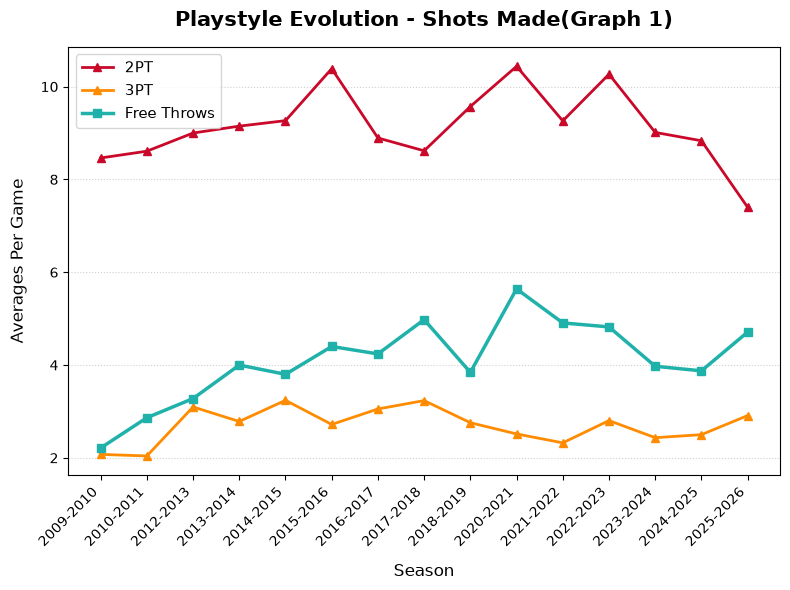

In [12]:
seasonal_data = df.groupby('Season')[['2PT', '3PT', 'Free Throws']].mean().reset_index()

plt.figure(figsize=(8, 6))

# Plotting

plt.plot(seasonal_data['Season'], seasonal_data['2PT'], color='#C9082A', marker='^', linewidth=2, label='2PT')
plt.plot(seasonal_data['Season'], seasonal_data['3PT'], color='#FF8C00', marker='^', linewidth=2, label='3PT')
plt.plot(seasonal_data['Season'], seasonal_data['Free Throws'], color='#20B2AA', marker='s', linewidth=2.5, label='Free Throws')

# Formatting
plt.title('Playstyle Evolution - Shots Made(Graph 1)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Season', fontsize=12, labelpad=10)
plt.ylabel('Averages Per Game', fontsize=12, labelpad=10)

# Rotating x label to fit
plt.xticks(rotation=45, ha='right')

# Adding legend
plt.legend(loc='upper left', fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Clean up layout
plt.tight_layout()
plt.show()

<span>
    <h5> 2PT - Steph's most contributing to score shot showing far above attempts made.<br>
         3PT - Major rise starting from 2012 to 2017 with a slight decrease in coming years.<br>
         Free Throws - showing major rise meaning more fouls have been made on Steph over the years.</h5>
</span>

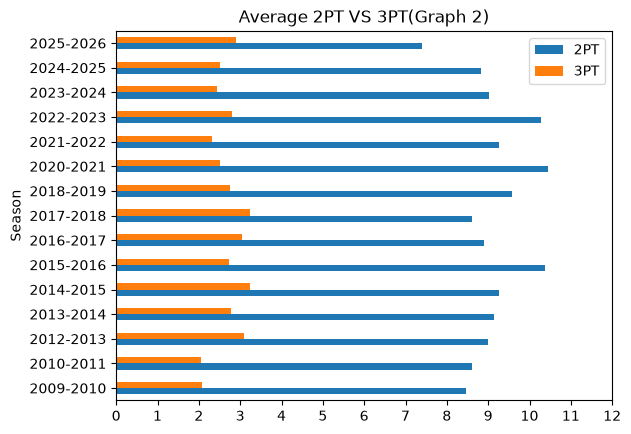

In [13]:
twopt_3pt = df.groupby('Season')[['2PT', '3PT']].mean()
ax = twopt_3pt.plot(kind="barh")

ax.set_title("Average 2PT VS 3PT(Graph 2)")
ax.set_ylabel("Season")
ax.set_xticks(np.arange(0,13,1))
plt.show()

<span>
    <h5> This graph above also clearly shows the dominance of 2PT shot over 3PT shot across all years</h5>
</span>

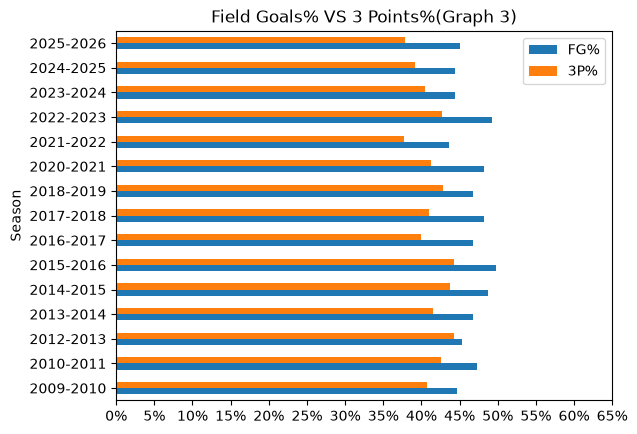

In [14]:
FG_PCT_3P_PCT = df.groupby('Season')[['FG%', '3P%']].mean()
ax = FG_PCT_3P_PCT.plot(kind="barh")

ax.set_title("Field Goals% VS 3 Points%(Graph 3)")
ax.set_ylabel("Season")
ax.set_xticks(np.arange(0,70,5))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100, decimals=0))
plt.show()

<span>
    <h5> Despite the previous graph, whenever Steph throws a 3PT shot, you can clearly see his percentages are extremely high and not too far from 2PT.</h5>
</span>

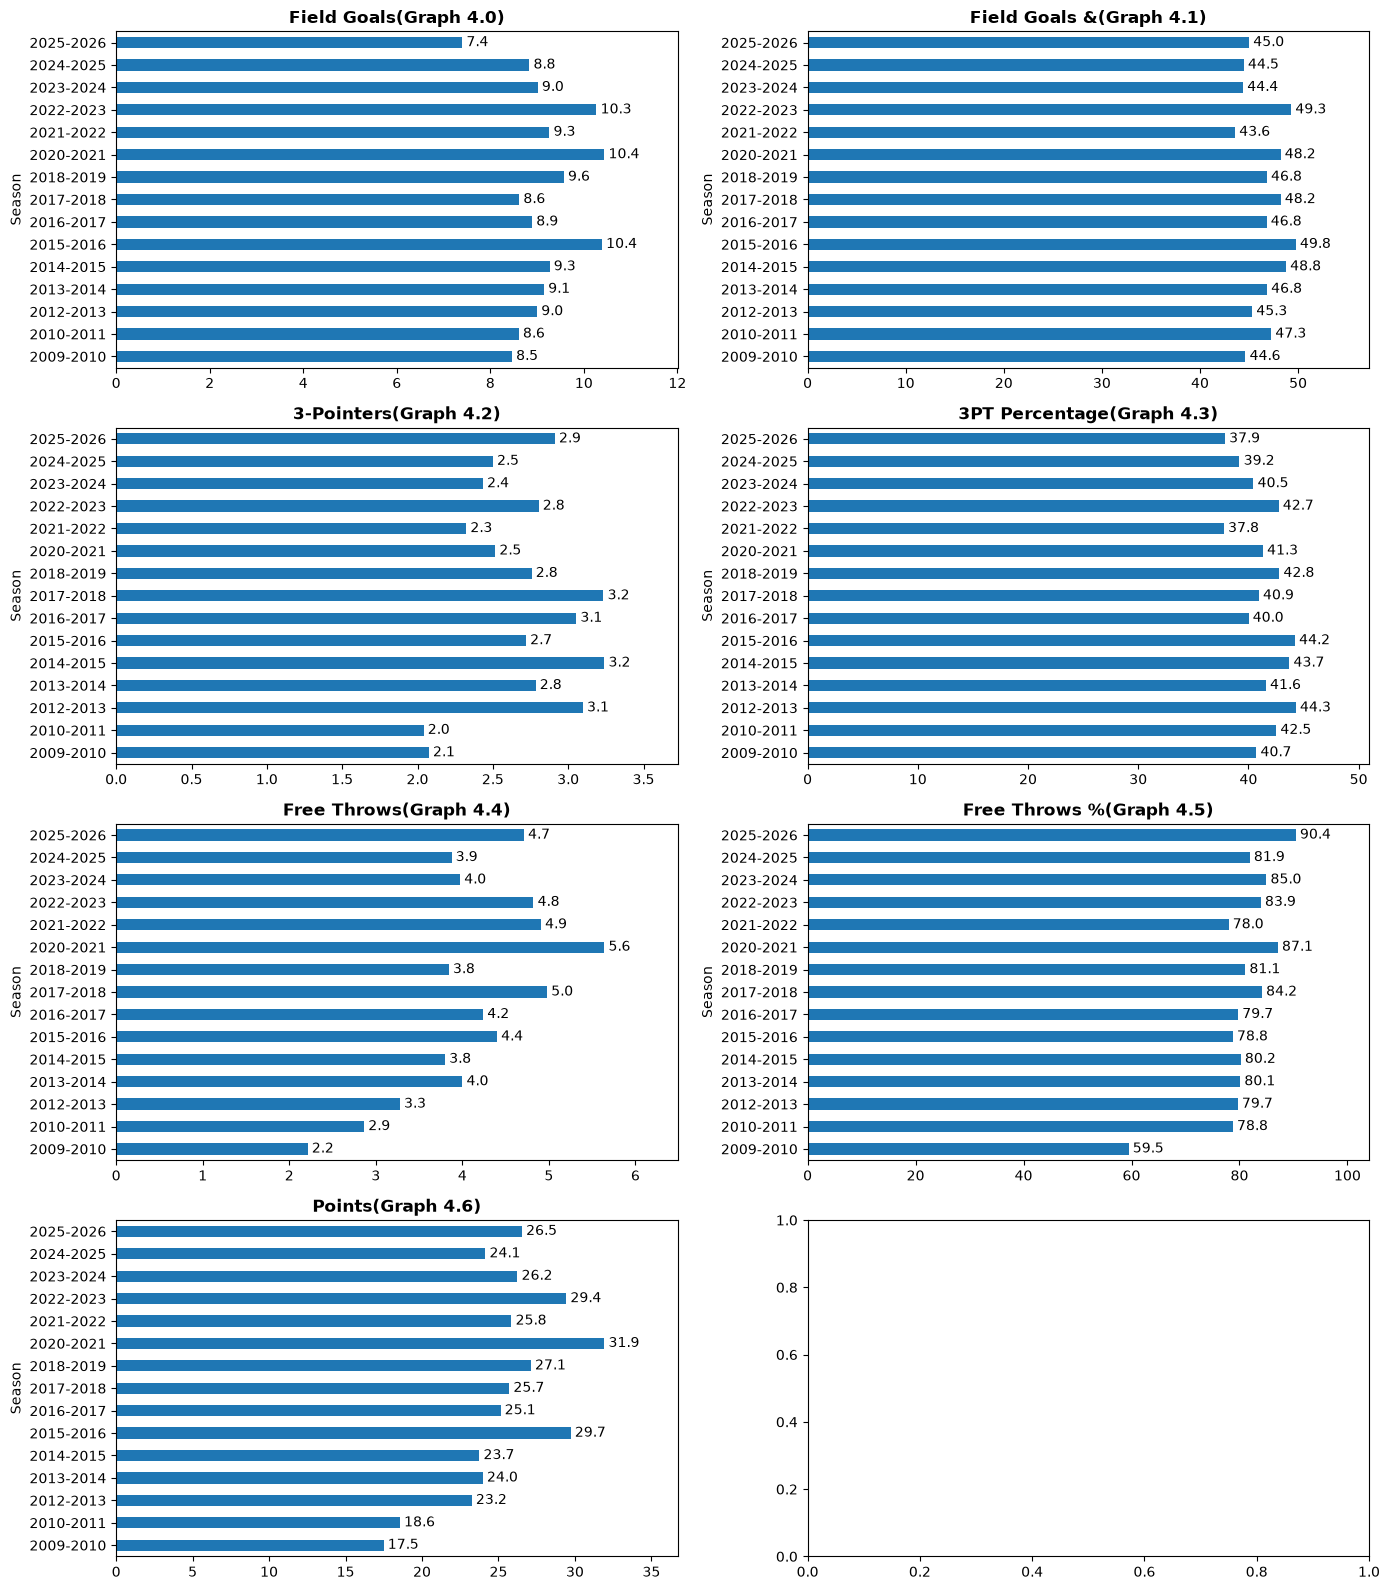

In [15]:
#Creating dictionary
metrics = {
    '2PT': 'Field Goals',
    'FG%': 'Field Goals &',
    '3PT': '3-Pointers',
    '3P%': '3PT Percentage',
    'Free Throws': 'Free Throws',
    'FT%': 'Free Throws %',
    'Points': 'Points'
}

# Creating grid
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 16))
axes_flat = axes.flatten()

# looping through metrics and ploting each
for i, (column, title) in enumerate(metrics.items()):
    ax = axes_flat[i]
    
    #Grouping by column
    data = df.groupby('Season')[column].mean()
    
    # Plot on the assigned axis
    data.plot(kind="barh", ax=ax)
    
    # Styling
    ax.set_title(title + f'(Graph 4.{i})', fontsize=12, fontweight='bold')
    ax.set_ylabel("Season")
    
    # Auto scaling
    ax.margins(x=0.15) 
    
    # Adding data on bar
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()

<span>
    <h4> Gathering other insight from major stats:</h4>
    <h5>Field Goals: Slight increase over the first two years with peaks in years 2015,2020 and 2022<br>
    Field Goals %: Slight increase.<br>
    3 Pointers: Major improvment after the first two years with peaks in years 2012,2014,2016 and 2017<br>
    3PT Percentage: Major improvement after the first two years with peaks in years 2012, 2014 and 2015<br>
    Free Throws: Major improvement after the first two year with peaks as 3 times higher.<br>
    Free Throws %: major improvement after the first two seasons.<br>
    Points: Major improvement after the first two years with peaks as twice as high.</h5>
</span>

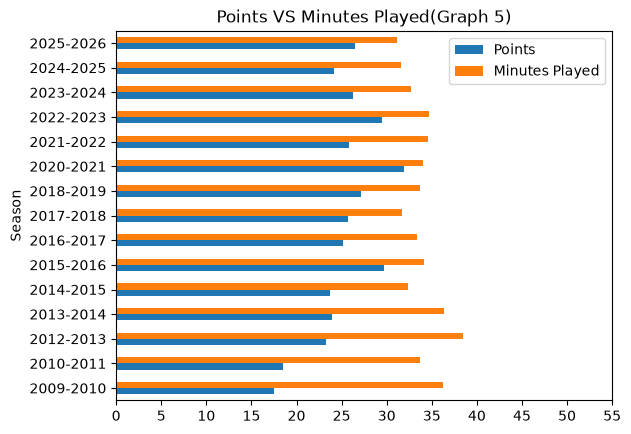

In [16]:
points_minutes_played = df.groupby('Season')[['Points', 'Minutes Played']].mean()
ax = points_minutes_played.plot(kind="barh")

ax.set_title("Points VS Minutes Played(Graph 5)")
ax.set_ylabel("Season")
ax.set_xticks(np.arange(0,60,5))
plt.show()

<span>
    <h5> This graph clearly illustrates how efficient in scoring Steph has become over the years<br>
         Also, as he built up his game through the years he had more and more ball possessions<br>
         Higher scoring = higher ball possessions</h5><br>
</span>

<span style="background-color: #fff3cd; padding: 2px 5px; border-left: 4px solid #ffc107; display: block;">
    <h3 style="color: #856404; margin: 5px 0;">2. What was Steph's contribution to winning games?</h3>
</span>

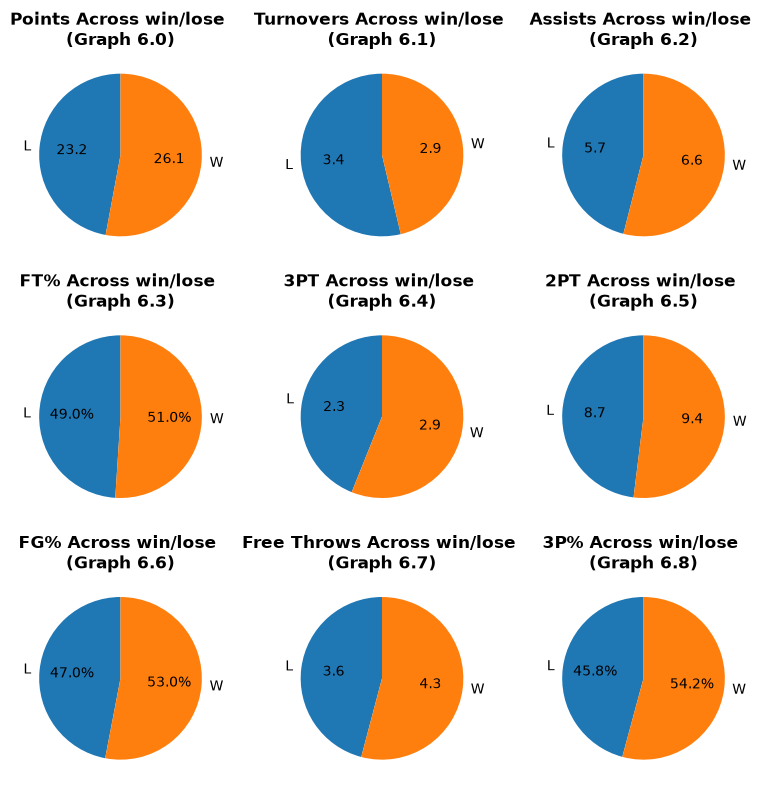

In [17]:
pie_columns = ['Points', 'Turnovers', 'Assists', 'FT%', '3PT','2PT' ,'FG%',  'Free Throws', '3P%']

# Assinging figuresize
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
axes_list = axes.flatten()

# Looping through columns and plotting each one
for i, col in enumerate(pie_columns):
    group_data = df.groupby('Result')[col].mean()
    column_total = group_data.sum()
    
    # Applying correct format to displayed numbers
    if '%' in col:
        current_autopct = '%1.1f%%'
    else:
        current_autopct = lambda pct, total=column_total: f'{pct * total / 100:.1f}'
        
    # Plotting
    group_data.plot(
        kind="pie",
            autopct=current_autopct,
            startangle=90,
            ax=axes_list[i]
    )
    #Setting Titles to each pie
    axes_list[i].set_title(f"{col} Across win/lose \n(Graph 6.{i})", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

<span>
    <h5> All graphs are dicisive, when Steph plays better(even by small margins) his team wins.<br>
         Standing out are FG% Across won/lose and 3p% across win/lose with higher margins.<br>
</span>

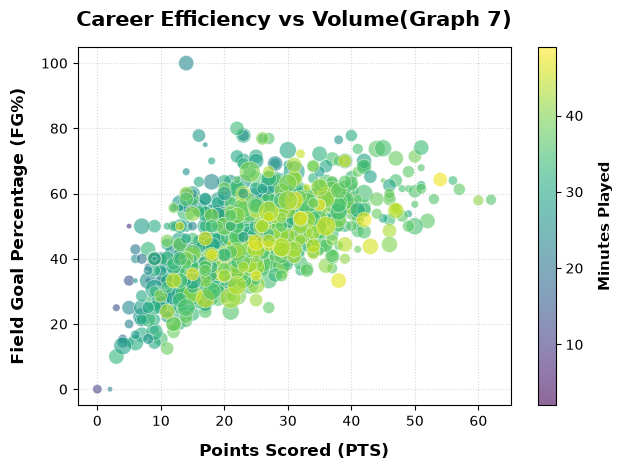

In [18]:
scatter = plt.scatter(
    df['Points'], df['FG%'], 
    s=df['Assists'] * 15, 
    c=df['Minutes Played'],    
    cmap='viridis', 
    alpha=0.6, 
    edgecolors='white',
    linewidths=0.5
)

# Minutes bar
cbar = plt.colorbar(scatter)
cbar.set_label('Minutes Played', fontsize=11, labelpad=10, fontweight='bold')

# labels and formatting
plt.title('Career Efficiency vs Volume(Graph 7)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Points Scored (PTS)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Field Goal Percentage (FG%)', fontsize=12, fontweight='bold', labelpad=10)
plt.grid(True, linestyle=':', alpha=0.5)

# Clean up layout
plt.tight_layout()
plt.show()

<span>
    <h5> This graph above shows how effecient Steph was in contributing to team score in two aspects<br>
         1. Over minuted played - He clearly had more % when played more<br>
         2. Over points scored - The more Points he scored the more Field goal percentage he had<br>
         Also, the majority of the games he played were roughly 30 minutes and above.<br>
</span>

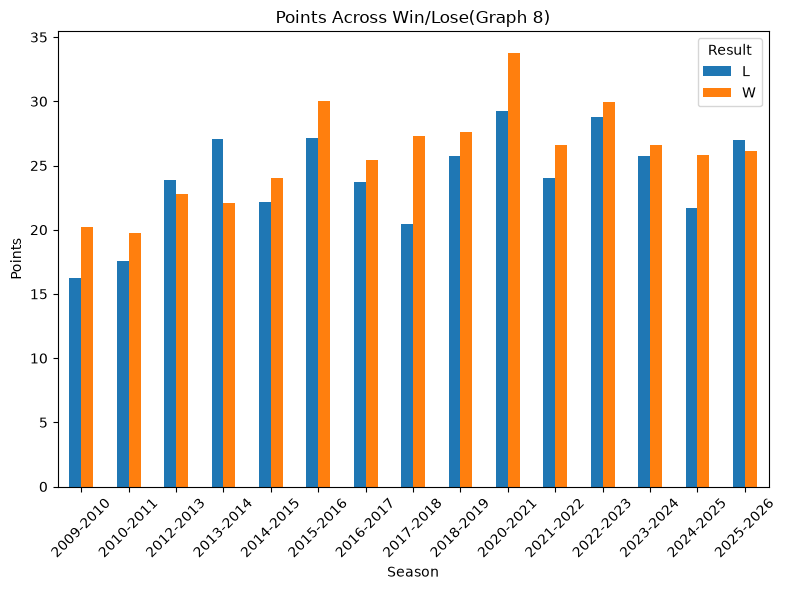

In [19]:
df.groupby(['Season', 'Result'])['Points'].mean().unstack().plot(kind='bar', figsize=(8, 6))

plt.title('Points Across Win/Lose(Graph 8)')
plt.xlabel('Season')
plt.ylabel('Points')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

<span>
    <h5> This graph above clearly shows that when Steph averaged more his team won<br>
         standing out are years 2012, 2013, 2026.<br>
</span>

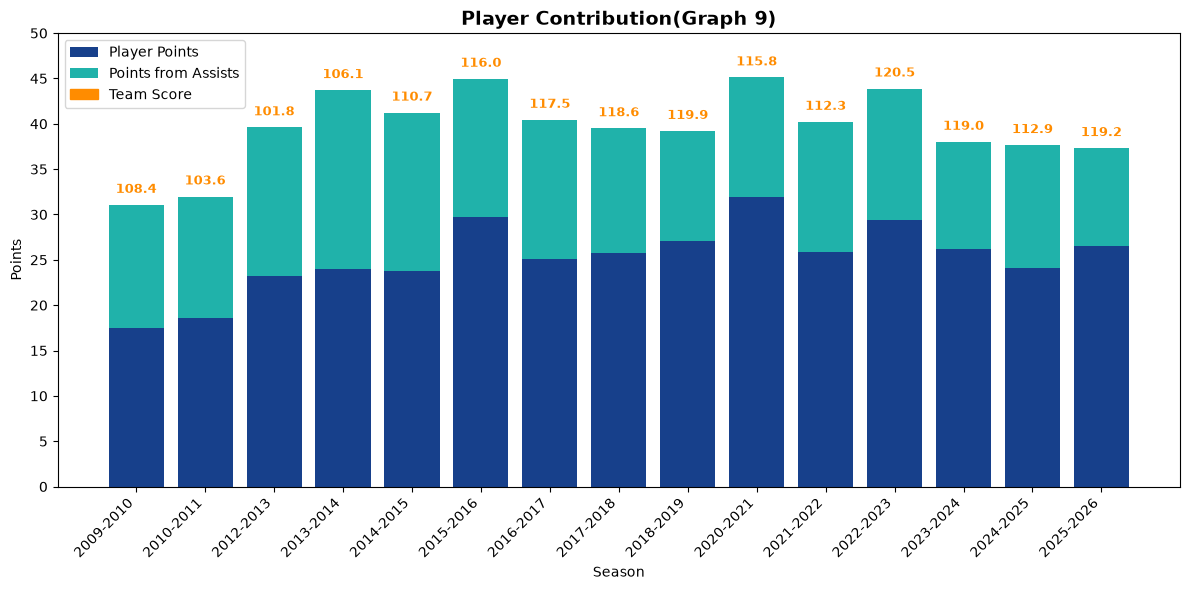

In [20]:
# Grabbing team score
df['Team_Score'] = np.where(df['Result'] == 'W', df['Winning Score'], df['Losing Score'])

# Calculating seasonal averages
seasonal_data = df.groupby('Season')[['Points', 'Assists', 'Team_Score']].mean().reset_index()

# Estimate points generated by player assists (2.3 points per assist)
pts_from_ast = seasonal_data['Assists'] * 2.3

plt.figure(figsize=(12, 6))

# Plotting bars
plt.bar(seasonal_data['Season'], seasonal_data['Points'], color='#17408B', label='Player Points')
plt.bar(seasonal_data['Season'], pts_from_ast, bottom=seasonal_data['Points'], color='#20B2AA', label='Points from Assists')

# Adding Team's Average Score
for i in range(len(seasonal_data)):
    # Calculating where the player's stacked bar ends
    player_total = seasonal_data['Points'].iloc[i] + pts_from_ast.iloc[i]
    team_avg = seasonal_data['Team_Score'].iloc[i]
    
    # Placing team average number slightly above the player's bar
    plt.text(
        i, player_total + 1.0, f"{team_avg:.1f}", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#FF8C00')

# Labels & legend formatting
plt.title('Player Contribution(Graph 9)', fontsize=14, fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Points')
plt.xticks(rotation=45, ha='right')
plt.yticks(np.arange(0,55,5))

# Adding team score to legend
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(mpatches.Patch(color='#FF8C00'))
labels.append('Team Score')

# Adding legend
plt.legend(handles=handles, labels=labels, loc='upper left')

plt.tight_layout()
plt.show()

<span>
    <h5> This graph above clearly illustrates Steph's contribution to team effort comparing to total team score!<br>
</span>

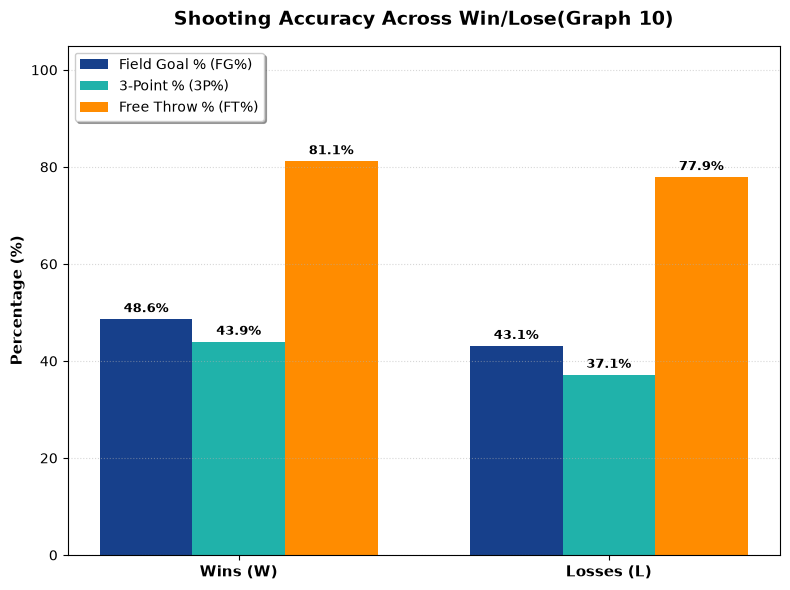

In [21]:
# Calculating average efficiency - Wins vs Losses
eff_splits = (
    df.groupby("Result")[["FG%", "3P%", "FT%"]].mean().reindex(["W", "L"]).reset_index()
)

fig, ax = plt.subplots(figsize=(8, 6))

# Bar spacings
x = np.arange(len(eff_splits["Result"]))
width = 0.25

# Plotting bars side-by-side
bar_fg = ax.bar(
    x - width, eff_splits["FG%"], width, label="Field Goal % (FG%)", color="#17408B"
)
bar_3p = ax.bar(
    x, eff_splits["3P%"], width, label="3-Point % (3P%)", color="#20B2AA"
)
bar_ft = ax.bar(
    x + width, eff_splits["FT%"], width, label="Free Throw % (FT%)", color="#FF8C00"
)

# Titles and Formatting
ax.set_title("Shooting Accuracy Across Win/Lose(Graph 10)", fontsize=14, fontweight="bold", pad=15)

ax.set_ylabel("Percentage (%)", fontsize=11, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(["Wins (W)", "Losses (L)"], fontsize=11, fontweight="bold")
ax.set_ylim(0, 105)  # Sets the roof slightly above 100% for label padding
ax.grid(axis="y", linestyle=":", alpha=0.5)

# Adding labels on top of all bars
ax.bar_label(bar_fg, fmt="%.1f%%", padding=3, fontsize=9, fontweight="bold")
ax.bar_label(bar_3p, fmt="%.1f%%", padding=3, fontsize=9, fontweight="bold")
ax.bar_label(bar_ft, fmt="%.1f%%", padding=3, fontsize=9, fontweight="bold")

# legend formatting
ax.legend(loc="upper left", frameon=True, shadow=True, facecolor="white")

plt.tight_layout()
plt.show()

<span>
    <h5> The above graph clearly shows that Steph's efficiency differs a lot across Win/Lose<br>
</span>

<span style="background-color: #fff3cd; padding: 2px 5px; border-left: 4px solid #ffc107; display: block;">
    <h3 style="color: #856404; margin: 5px 0;">3. Did the facility location (Home/Away) impact Steph's game?</h3>
</span>

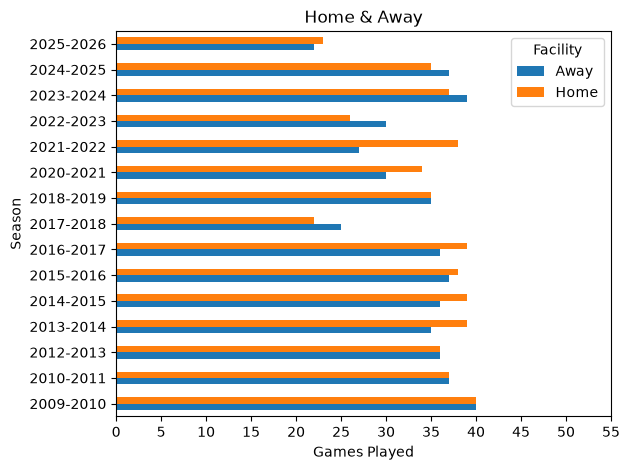

In [22]:
table = pd.crosstab(index=df['Season'], columns=df['Facility'])
table.plot(kind ='barh')
plt.title('Home & Away')
plt.xlabel('Games Played')
plt.xticks(np.arange(0,60,5))
plt.tight_layout()

<span>
    <h5> Home VS Away games slightly tipping in favor of home.<br>
</span>

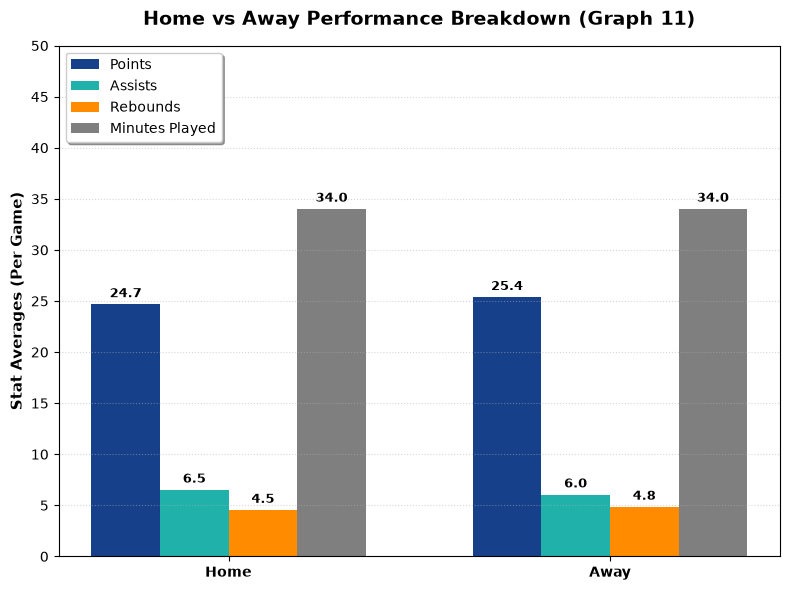

In [23]:
splits = (
    df.groupby(["Facility"])
    .agg(
        Games=("Points", "count"),
        Points=("Points", "mean"),
        Assists=("Assists", "mean"),
        Rebounds=("Rebound", "mean"),
        Turnovers=("Turnovers", "mean"),
        FG_Pct=("FG%", "mean"),
        Minutes=("Minutes Played", "mean"),
    )
    .reset_index()
)

# Create clean text labels using just the Facility name
splits["Category"] = splits["Facility"]
# Sorting
splits = splits.sort_values(by=["Facility"], ascending=False)

fig, ax1 = plt.subplots(figsize=(8, 6))

# Plotting all metrics as grouped bars
x = np.arange(len(splits["Category"]))
width = 0.18  # Width of each individual bar

bar1 = ax1.bar(x - 1.5*width, splits["Points"], width, label="Points", color="#17408B")
bar2 = ax1.bar(x - 0.5*width, splits["Assists"], width, label="Assists", color="#20B2AA")
bar3 = ax1.bar(x + 0.5*width, splits["Rebounds"], width, label="Rebounds", color="#FF8C00")
bar4 = ax1.bar(x + 1.5*width, splits["Minutes"], width, label="Minutes Played", color="#7F7F7F")

# Formatting
ax1.set_title("Home vs Away Performance Breakdown (Graph 11)", fontsize=14, fontweight="bold", pad=15)
ax1.set_ylabel("Stat Averages (Per Game)", fontsize=11, fontweight="bold")
ax1.set_yticks(np.arange(0, 55, 5)) 
ax1.set_xticks(x)
ax1.set_xticklabels(splits["Category"], fontsize=10, fontweight="bold")
ax1.grid(axis="y", linestyle=":", alpha=0.5)

# Adding data labels
ax1.bar_label(bar1, fmt='%.1f', padding=3, fontsize=9, fontweight='bold')
ax1.bar_label(bar2, fmt='%.1f', padding=3, fontsize=9, fontweight='bold')
ax1.bar_label(bar3, fmt='%.1f', padding=3, fontsize=9, fontweight='bold')
ax1.bar_label(bar4, fmt='%.1f', padding=3, fontsize=9, fontweight='bold')

# Placing legend
ax1.legend(loc="upper left", frameon=True, shadow=True, facecolor="white")

plt.tight_layout()
plt.show()

<span>
    <h5> Minor diffrences, some leaning towards away.<br>
</span>

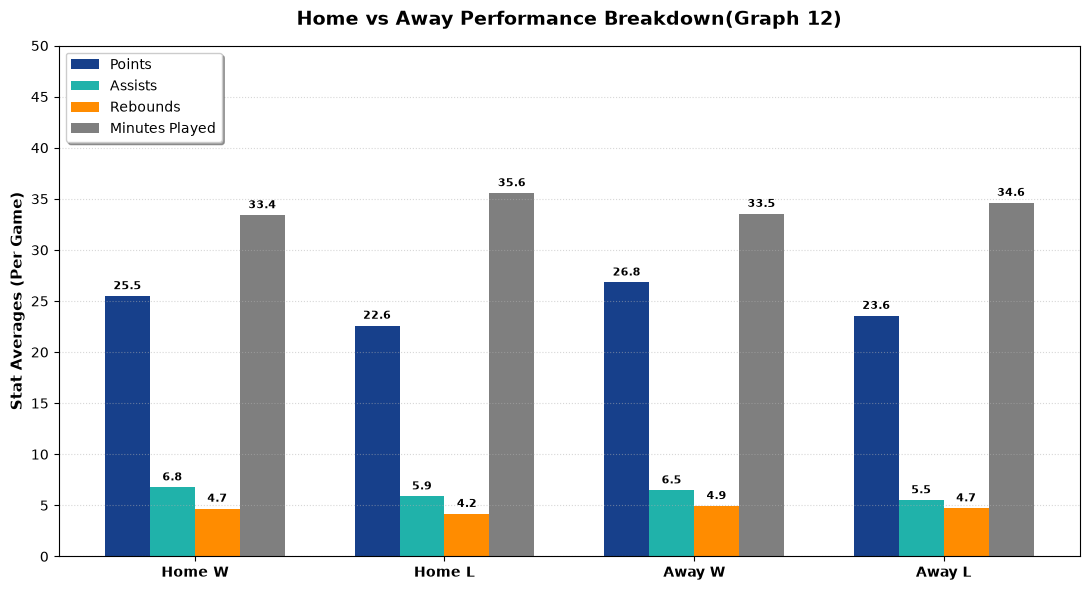

In [24]:
splits = (
    df.groupby(["Facility", "Result"])
    .agg(
        Games=("Points", "count"),
        Points=("Points", "mean"),
        Assists=("Assists", "mean"),
        Rebounds=("Rebound", "mean"),
        Turnovers=("Turnovers", "mean"),
        FG_Pct=("FG%", "mean"),
        Minutes=("Minutes Played", "mean"),
    )
    .reset_index()
)

# Creating text labels
splits["Category"] = splits["Facility"] + " " + splits["Result"]
# Sort to order
splits = splits.sort_values(by=["Facility", "Result"], ascending=[False, False])

# Chart layout
fig, ax1 = plt.subplots(figsize=(11, 6))

# Plotting all metrics as grouped bars
x = np.arange(len(splits["Category"]))
width = 0.18  # Narrowed slightly

bar1 = ax1.bar(x - 1.5*width, splits["Points"], width, label="Points", color="#17408B")
bar2 = ax1.bar(x - 0.5*width, splits["Assists"], width, label="Assists", color="#20B2AA")
bar3 = ax1.bar(x + 0.5*width, splits["Rebounds"], width, label="Rebounds", color="#FF8C00")
bar4 = ax1.bar(x + 1.5*width, splits["Minutes"], width, label="Minutes Played", color="#7F7F7F")

# Formatting
ax1.set_title("Home vs Away Performance Breakdown(Graph 12)", fontsize=14, fontweight="bold", pad=15,)
ax1.set_ylabel("Stat Averages (Per Game)", fontsize=11, fontweight="bold")
ax1.set_yticks(np.arange(0, 55, 5)) 
ax1.set_xticks(x)
ax1.set_xticklabels(splits["Category"], fontsize=10, fontweight="bold")
ax1.grid(axis="y", linestyle=":", alpha=0.5)

# Adding data labels
ax1.bar_label(bar1, fmt='%.1f', padding=3, fontsize=8, fontweight='bold')
ax1.bar_label(bar2, fmt='%.1f', padding=3, fontsize=8, fontweight='bold')
ax1.bar_label(bar3, fmt='%.1f', padding=3, fontsize=8, fontweight='bold')
ax1.bar_label(bar4, fmt='%.1f', padding=3, fontsize=8, fontweight='bold')

# Placing legend
ax1.legend(loc="upper left", frameon=True, shadow=True, facecolor="white")

plt.tight_layout()
plt.show()

<span>
    <h5> Even when further breaking it down to win lose, minor differences, ambiguous and some even leaning towards Away L.<br>
</span>

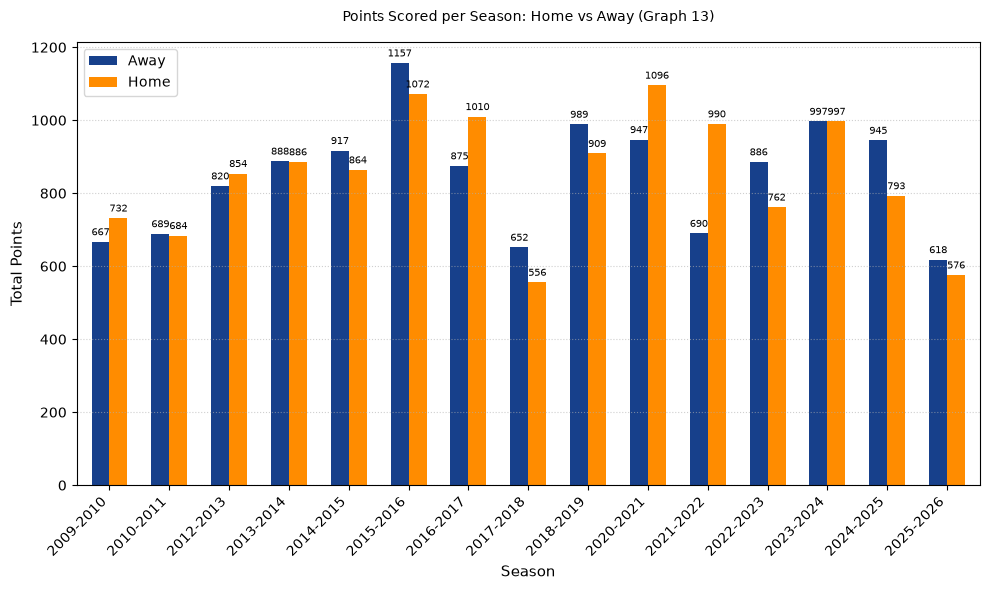

In [25]:
# Grouping
season_facility_points = df.groupby(["Season", "Facility"])["Points"].sum().unstack(fill_value=0)

# Plotting
ax = season_facility_points.plot(kind="bar", stacked=False, figsize=(10, 6), color=["#17408B", "#FF8C00"], width=0.6)

# labeling and formatting
plt.title("Points Scored per Season: Home vs Away (Graph 13)", fontsize=10, pad=15)
plt.ylabel("Total Points", fontsize=11)
plt.xlabel("Season", fontsize=11)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(["Away", "Home"], loc="upper left")

# Rotating X-axis season labels to 45 degrees
plt.xticks(rotation=45, ha="right")  # ha="right" ensures the labels line up nicely under the ticks

# Adding data labels on bar
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=7)

plt.tight_layout()
plt.show()

<span>
    <h5> Even when looking into points per season data is ambiguous and slightly leaning towards Away.<br>
</span>

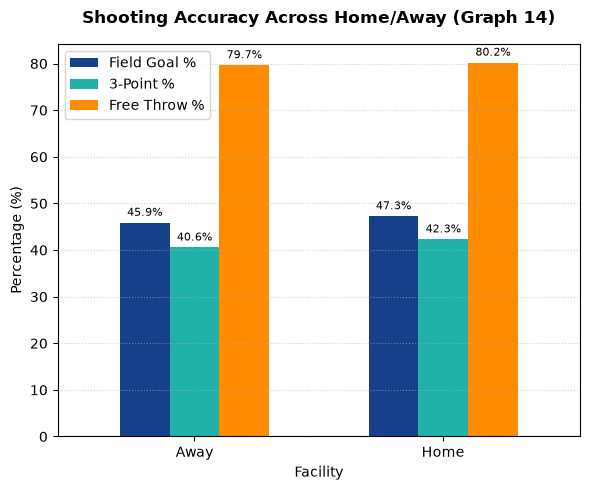

In [26]:
shooting_splits = df.groupby("Facility")[["FG%", "3P%", "FT%"]].mean()

# Plotting
ax = shooting_splits.plot(kind="bar", figsize=(6, 5), width=0.6, color=["#17408B", "#20B2AA", "#FF8C00"])

# labels and formatting
plt.title("Shooting Accuracy Across Home/Away (Graph 14)", fontsize=12, fontweight="bold", pad=15)
plt.ylabel("Percentage (%)", fontsize=10)
plt.xlabel("Facility", fontsize=10)
plt.xticks(rotation=0) 
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(["Field Goal %", "3-Point %", "Free Throw %"], loc="upper left")

# Asigning values on bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

<span>
    <h5> Minor efficiency differences across Home/Away.<br>
</span>

<span style="background-color: #fff3cd; padding: 2px 5px; border-left: 4px solid #ffc107; display: block;">
    <h3 style="color: #856404; margin: 5px 0;">4. What is Steph's best shot?</h3>
</span>

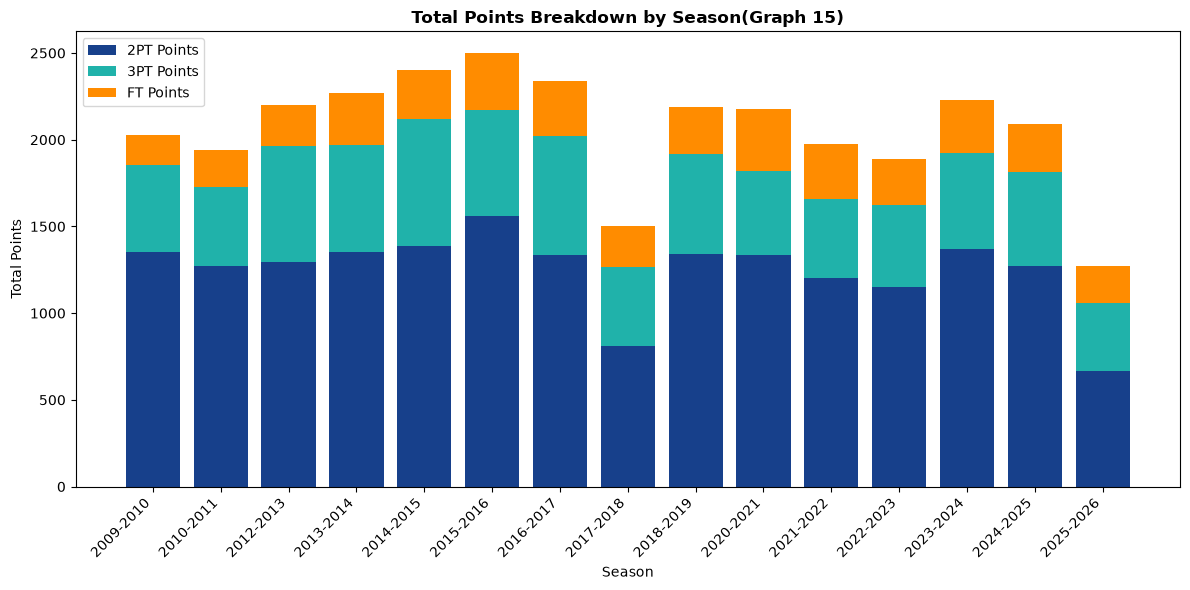

In [27]:
df_season = df.groupby("Season")[["2PT", "3PT", "Free Throws"]].sum().reset_index()

# point conversion
p2, p3, pft = df_season["2PT"] * 2, df_season["3PT"] * 3, df_season["Free Throws"]

# Plotting stacked bars
plt.figure(figsize=(12, 6))
plt.bar(df_season["Season"], p2, color="#17408B", label="2PT Points")
plt.bar(df_season["Season"], p3, bottom=p2, color="#20B2AA", label="3PT Points")
plt.bar(df_season["Season"], pft, bottom=p2 + p3, color="#FF8C00", label="FT Points")

# Labels and formatting
plt.title("Total Points Breakdown by Season(Graph 15)", fontweight="bold")
plt.xlabel("Season")
plt.ylabel("Total Points")
plt.xticks(rotation=45, ha="right")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

<span>
    <h5> Anlyzing shots in raw numbers to see that Steph's best score contributing shot is 2PT.<br>
</span>

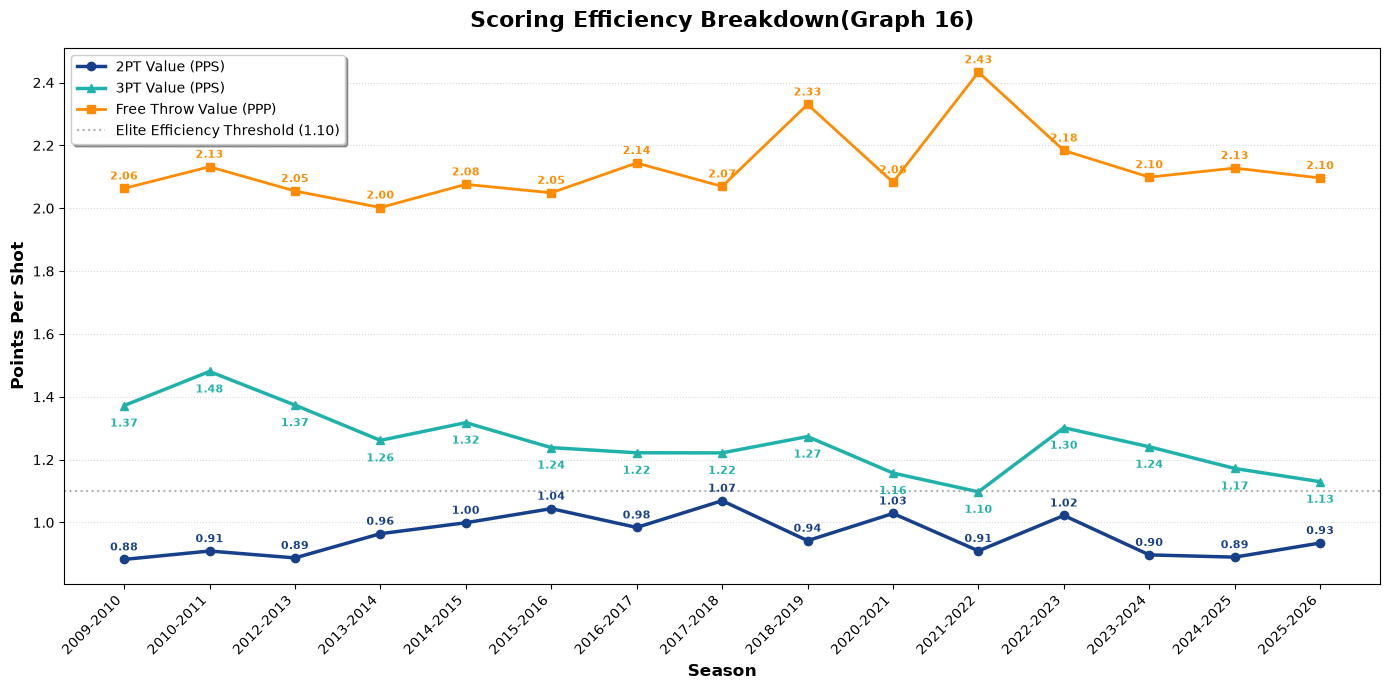

In [28]:
# Adding columns
df["3PM"] = df["3PT"]
df["2PM"] = df["2PT"]
df["FGM"] = df["2PM"] + df["3PM"]
df["FTM"] = df["Free Throws"]

# Calculating new stats
df["FGA"] = np.where(df["FG%"] > 0, (df["FGM"] / (df["FG%"] / 100)), 0)
df["3PA"] = np.where(df["3P%"] > 0, (df["3PM"] / (df["3P%"] / 100)), 0)
df["2PA"] = df["FGA"] - df["3PA"]
df["FTA"] = np.where(df["FT%"] > 0, (df["FTM"] / (df["FT%"] / 100)), 0)

# Grouping everything by season to aggregate totals over all games
career_evolution = (
    df.groupby("Season")
    .agg(
        Total_2PM=("2PM", "sum"),
        Total_2PA=("2PA", "sum"),
        Total_3PM=("3PM", "sum"),
        Total_3PA=("3PA", "sum"),
        Total_FTM=("FTM", "sum"),
        Total_FTA=("FTA", "sum"),
    )
    .reset_index()
)

# Calculating true career Points Per Shot (PPS) and Points Per Possession (PPP)
career_evolution["2PT_PPS"] = (career_evolution["Total_2PM"] * 2) / career_evolution["Total_2PA"]
career_evolution["3PT_PPS"] = (career_evolution["Total_3PM"] * 3) / career_evolution["Total_3PA"]
career_evolution["FT_PPP"] = career_evolution["Total_FTM"] / (career_evolution["Total_FTA"] * 0.44)
career_evolution.fillna(0, inplace=True)

plt.figure(figsize=(14, 7))

# Plotting three stats
plt.plot(career_evolution["Season"], career_evolution["2PT_PPS"], color="#17408B", marker="o", linewidth=2.5, label="2PT Value (PPS)")
plt.plot(career_evolution["Season"], career_evolution["3PT_PPS"], color="#20B2AA", marker="^", linewidth=2.5, label="3PT Value (PPS)")
plt.plot(career_evolution["Season"], career_evolution["FT_PPP"], color="#FF8C00", marker="s", linewidth=2, label="Free Throw Value (PPP)")

# Adding analytical benchmark line (1.10 PPS is considered highly elite scoring)
plt.axhline(y=1.10, color="gray", linestyle=":", alpha=0.6, label="Elite Efficiency Threshold (1.10)")

# Adding text labels
for i in range(len(career_evolution)):
    plt.text(
        i, career_evolution["2PT_PPS"].iloc[i] + 0.02,
        f"{career_evolution['2PT_PPS'].iloc[i]:.2f}",
        ha="center", va="bottom", fontsize=8, color="#17408B", fontweight="bold"
    )
    plt.text(
        i, career_evolution["3PT_PPS"].iloc[i] - 0.04,
        f"{career_evolution['3PT_PPS'].iloc[i]:.2f}",
        ha="center", va="top", fontsize=8, color="#20B2AA", fontweight="bold"
    )
    plt.text(i, career_evolution["FT_PPP"].iloc[i] + 0.02,
        f"{career_evolution['FT_PPP'].iloc[i]:.2f}",
        ha="center", va="bottom", fontsize=8, color="#FF8C00", fontweight="bold"
    )

# styling and formatting
plt.title("Scoring Efficiency Breakdown(Graph 16)", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Season", fontsize=12, fontweight="bold")
plt.ylabel("Points Per Shot", fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle=":", alpha=0.5)

# Adding legend
plt.legend(loc="upper left", frameon=True, shadow=True, facecolor="white")

plt.tight_layout()
plt.show()

<span>
    <h5> However, when put into context by adding new PPS & PPP stats you can see that 3PT shot rises well above 2PT shot.<br>
The above graph clearly shows that Steph's Free throw shot is his "best" shot. however some would argue as this shot is static and not during live play.<br>
</span>

## Analysis Conclusions:

1. #### How did Steph evolve during the years since draft up to current Season?
    
	Over the years, Steph's most contributing to score shot is 2PT (Graphs 1, 2)<br>
	Amazing 3PT percentage was kept throuout the years with higher percentages in 2PT(Graph 3)<br>
	2PT slightly improved(Graph 4.0) while 3PT showed greater improvements(Graph 4.2)<br>
	Over the years, Steph drew more fouls resulting in more Free Throws(Graph 4.4). He also significantly improved in Free Throws percentage(Graph 4.5)<br>
	Steph has built his game over the years resulting in higher points per game.(Graph 4.6)<br>
	Amazing efficiency improvement over the years with more and more ball possessions &amp; scoring(Graph 5)<br>
	Also, this is a classic representation of game style shift. A star was born with more ball possessions and much more scoring per minute play(Graph 5)<br>
    Another enormous improvement in Steph's game is Free Throw Percentage who this year has earned him a spot in the "90% elite club"<br>
    Making 9 out of every 10 Free Throw shot(Graph 4.5)<br>
	
3. #### What was Steph's contribution to winning games?
	
	When Steph plays better(even by small margins) his team usually wins(Graphs 6.X)<br>
	When Steph averaged more his team won, standing out are years 2012, 2013, 2026(Graph 8)<br>
	Most contributing to win were his 2PT percentages &amp; 3PT percentages(Graphs 6.X)<br>
	Steph has possitive correlation between Field Goal percentage and points scored.(Graph 7)<br>
	Steph is also a dominant player who averages 34 minutes per game.(full game =  48 Minutes)(Graph 11)<br>
	Steph's scoring ability combined with points from assists have enormously contributed to his team winning<br>
	With peaks of 40% point contribution(Graph 9)<br>
		
4. #### Did facility location (Home/Away) impact Steph's game?
	
	Analyzing Home and Away games shows that Steph was almost indifferent to the game location.<br>
	With slight changes and ambiguous stats, some even leaning towards away lost games(Graphs 11, 12 &amp; 13).<br>
	However, when it comes to efficiency, you can see that in home games Steph did perform slightly better(Graph 14).<br>
		
5. #### What is Steph's best shot?
	
	In raw numbers and dry stats, 2PT is the most contributing shot to score Steph has.(Graph 15)<br>
	However, when calculating new PPS &amp; PPP stats 3PT rises well above 2PT shot touching the Elite line from above merely once.<br>
	Also, it is the 3PT shot that made Steph able to penetrate and score 2PT so efficiently, in many cases even being double teamed.<br>
	
	In my opinion, 3PT shot is what makes Steph the game changer he is.<br>
	Back in the days, shooting a three pointer was considerred a bad choice due to lower percentage,<br>
	But when Steph showed high percentages even when shooting way behind the three point line<br>
	It clearly changed the NBA game forcing teams to adjust.<br>
	
	I can only talk so much about Steph's 3PT amazing ability but you have to withness it to believe:<br>
	https://www.youtube.com/watch?v=xbVOipRS2rc<br>
	https://www.youtube.com/watch?v=xt5vzE0QCvk<br>